# KLG Claims | IBCS-inspired Exploratory Data Analysis

**Decision question:** How can the claims team understand the current register and prioritise cases without confusing claim volume with true shipment risk?

**Scope:** This notebook analyses the claims register in `Data studenten (1).xlsx`. It is deliberately descriptive. Because normal shipments are missing, the notebook reports *recorded claim volume* and *outcome rates among known claims*, not a carrier or route risk rate.

**IBCS-inspired visual rules used here**
- one chart = one message;
- titles state the message, subtitles state the denominator;
- grey = context, blue = focus, red = data-quality/problem signal;
- direct labels instead of legends where possible;
- no 3D, gradients, unnecessary borders or decorative effects;
- exact values and source notes remain visible;
- every percentage has an explicit base.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import display, Markdown, HTML

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 42)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

# ---------- Reproducible setup ----------
search_dirs = [Path.cwd()]
if "__file__" in globals():
    search_dirs.append(Path(__file__).resolve().parent)
DATA_PATH = next((p / "Data studenten (1).xlsx" for p in search_dirs if (p / "Data studenten (1).xlsx").exists()), None)
if DATA_PATH is None:
    xlsx = list(Path.cwd().glob("*.xlsx"))
    if len(xlsx) == 1: DATA_PATH = xlsx[0]
    else: raise FileNotFoundError("Data studenten (1).xlsx was not found next to the notebook or in the working directory.")

raw = pd.read_excel(DATA_PATH, sheet_name="Data")
raw.columns = raw.columns.str.strip()
df = raw.copy()

NAVY = "#1F4E79"
BLUE = "#4472C4"
MID_GREY = "#A6A6A6"
LIGHT_GREY = "#D9E1F2"
DARK_GREY = "#404040"
RED = "#C00000"
ORANGE = "#ED7D31"
GREEN = "#70AD47"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.labelsize": 10, "figure.dpi": 130, "savefig.dpi": 160,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": False, "axes.titlepad": 18, "xtick.color": DARK_GREY, "ytick.color": DARK_GREY
})

def clean_text(s):
    return s.astype("string").str.strip().str.upper().replace({"": pd.NA, "<NA>": pd.NA})

def label_bars(ax, horizontal=True, percent=False, offset=0.015):
    values = ax.containers[0].datavalues
    for i, value in enumerate(values):
        label = f"{value:.1f}%" if percent else f"{value:,.0f}"
        if horizontal: ax.text(value + max(values) * offset, i, label, va="center", fontsize=9, color=DARK_GREY)
        else: ax.text(i, value + max(values) * offset, label, ha="center", va="bottom", fontsize=9, color=DARK_GREY)

def chart_frame(title, subtitle, source="Source: KLG claims register, Data sheet; author analysis"):
    fig, ax = plt.subplots(figsize=(11, 5.8), constrained_layout=True)
    ax.set_title(title, loc="left", color=DARK_GREY, fontweight="bold", pad=22)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, ha="left", va="bottom", color="#666666", fontsize=9)
    ax.text(0, -0.16, source, transform=ax.transAxes, ha="left", va="top", color="#666666", fontsize=8)
    ax.grid(axis="x", color="#E6E6E6", linewidth=.8); ax.set_axisbelow(True)
    return fig, ax

def finish(ax):
    ax.spines["bottom"].set_color("#BFBFBF")
    ax.tick_params(axis="y", length=0)
    plt.tight_layout(pad=1.5); plt.show()

def kpi_card(label, value, note, colour=NAVY):
    return f'''<div style="display:inline-block; width:22%; margin:0.8%; padding:14px; border-top:5px solid {colour}; background:#F2F2F2; vertical-align:top; min-height:75px"><div style="font-size:12px;color:#666">{label}</div><div style="font-size:25px;font-weight:bold;color:{colour}">{value}</div><div style="font-size:11px;color:#666">{note}</div></div>'''

# Standardise the main text fields and create analysis fields.
text_cols = ["CLAIM/KLACHT", "TERECHT?", "EXTERN KLANT GEMELD", "INCIDENT TYPE", "FOOD/FEED",
             "Vervoerder veroorzaker", "Afzender veroorzaker", "Cliam nog open", "Actie klant"]
for col in text_cols:
    if col in df.columns: df[col] = clean_text(df[col])
df["DOSSIERNR"] = pd.to_numeric(df["DOSSIERNR"], errors="coerce")
df["TRANSPORTDATUM"] = pd.to_datetime(df["TRANSPORTDATUM"], errors="coerce")
df["valid_dossier"] = df["DOSSIERNR"].notna()
df["transport_month"] = df["TRANSPORTDATUM"].dt.to_period("M").astype("string")
df["transport_weekday"] = df["TRANSPORTDATUM"].dt.day_name()

print(f"Source file: {DATA_PATH.name}")
print(f"Raw rows: {len(raw):,} | Source columns: {len(raw.columns)}")

Source file: Data studenten (1).xlsx
Raw rows: 2,032 | Source columns: 24


## 1 | Executive scorecard

### Why this section matters
Before looking at patterns, we need to define the population being analysed. The Excel file contains raw rows, but not every row is a complete dossier. This scorecard makes the base population visible and prevents later percentages from being misunderstood.

### How to read the results
- **Analytical dossiers** are rows with a `DOSSIERNR`.
- **Known outcomes** are rows where `TERECHT?` is `JA` or `NEE`.
- **Unknown target** includes `ONBEKEND` and blank/variant values that cannot be used as a reliable label.
- **Incident labels** are the number of different text values before business grouping.

The cards are not performance targets. They describe the shape and usability of the current dataset.

In [2]:
analysis = df[df["valid_dossier"]].copy()
known = analysis[analysis["TERECHT?"].isin(["JA", "NEE"])].copy()
valid_transport = analysis[analysis["TRANSPORTDATUM"].notna()]
claim_n = len(analysis)
known_n = len(known)
missing_n = len(analysis) - known_n
incident_n = analysis["INCIDENT TYPE"].nunique(dropna=True)

html = (kpi_card("Analytical dossiers", f"{claim_n:,}", "of 2,032 raw rows", NAVY)
        + kpi_card("Known outcomes", f"{known_n:,}", f"{known_n/claim_n:.1%} of dossiers", BLUE)
        + kpi_card("Unknown target", f"{missing_n:,}", "not usable as labels", ORANGE)
        + kpi_card("Incident labels", f"{incident_n:,}", "before business grouping", RED))
display(HTML(f"<div style='width:100%;font-family:Arial'>{html}</div>"))

scorecard = pd.DataFrame({
    "Metric": ["Raw rows", "Rows with dossier number", "Known JA/NEE outcomes", "Unknown/missing outcome", "Incident labels", "Missing shipment", "Missing transport date"],
    "Value": [len(raw), len(analysis), len(known), claim_n-known_n, incident_n, analysis["SHIPMENT"].isna().sum(), analysis["TRANSPORTDATUM"].isna().sum()],
    "Definition": ["All rows in Excel", "Analytical base", "JA or NEE only", "ONBEKEND or blank", "Unique non-empty labels", "SHIPMENT is empty", "TRANSPORTDATUM is empty"]
})
display(scorecard)

,Metric,Value,Definition
0,Raw rows,2032,All rows in Excel
1,Rows with dossier number,2019,Analytical base
2,Known JA/NEE outcomes,1724,JA or NEE only
3,Unknown/missing outcome,295,ONBEKEND or blank
4,Incident labels,105,Unique non-empty labels
5,Missing shipment,106,SHIPMENT is empty
6,Missing transport date,6,TRANSPORTDATUM is empty


## 2 | Data quality scorecard

### What this chart answers
Which fields lose the most usable information before analysis starts? The bars show the number of missing values in the 2,019-dossier analytical base.

### How to read the chart
Read the bars from top to bottom. Red bars identify fields that can directly affect modelling or interpretation, such as shipment ID, transport date, incident type and the target. Grey bars are still important, but are mainly process or supporting fields. The percentage printed at the end of each bar is the missing share of all analytical dossiers.

### Business meaning
A missing shipment number should be reported as a data-quality issue, not filled with a guessed value. Missingness can also be retained as a flag because it may describe a process weakness. The table below checks duplicates, invalid references, sparse costs and mixed date formats.

/var/folders/pt/qmvtwr7n04gfnygng_ks6vgm0000gn/T/ipykernel_8426/2603511730.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=1.5); plt.show()


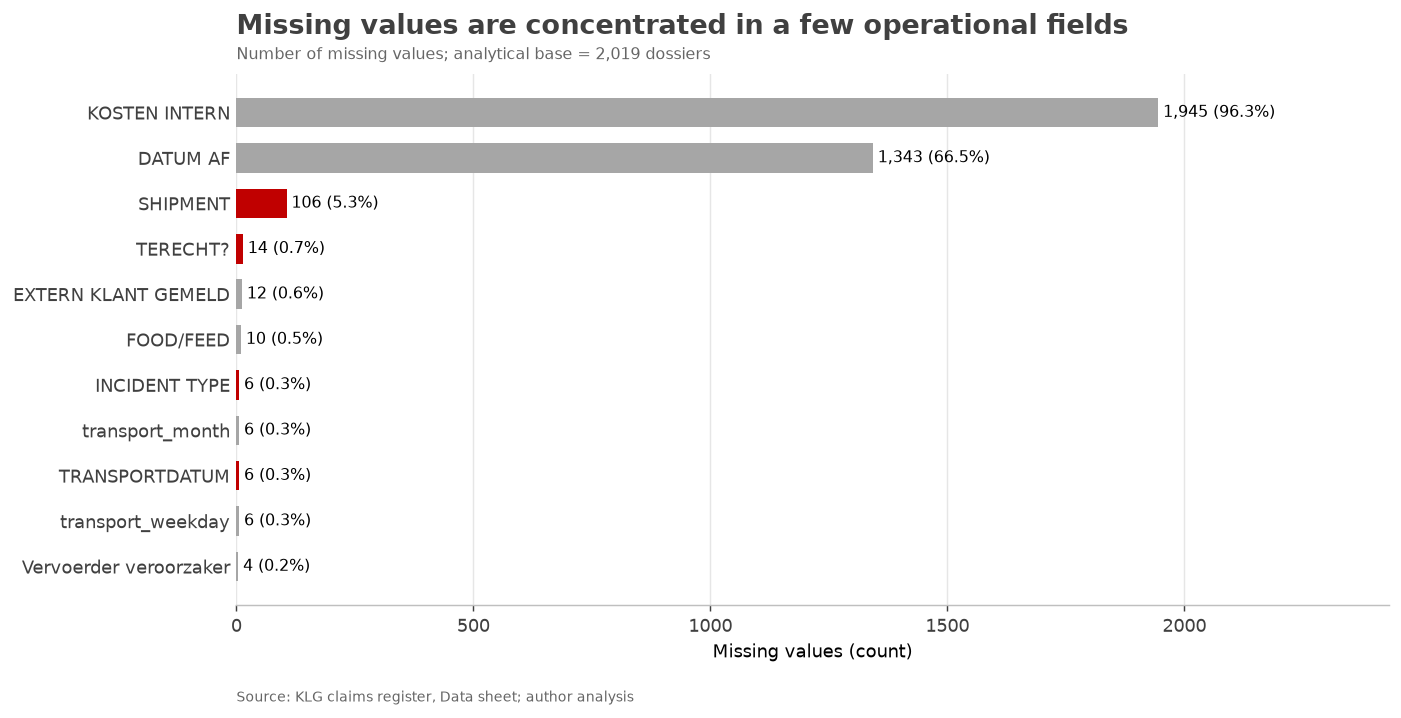

,Check,Result,Interpretation
0,DOSSIERNR duplicate,0,Should be 0
1,SHIPMENT duplicate,105,Should be 0 for one shipment per row
2,Rows without dossier,13,Exclude from modelling
3,Vervoerder veroorzaker = #REF!,0,Invalid formula/reference
4,Numeric internal costs,31,Too sparse for first model
5,Closing dates as datetime,0,Mixed date format
6,Closing dates as text,398,Mixed date format


In [3]:
quality = pd.DataFrame({
    "missing": analysis.isna().sum(),
    "missing_%": analysis.isna().mean() * 100,
    "unique": analysis.nunique(dropna=True),
    "dtype": analysis.dtypes.astype(str)
}).sort_values("missing", ascending=False)

quality_view = quality[quality["missing"] > 0].head(15).sort_values("missing")
fig, ax = chart_frame("Missing values are concentrated in a few operational fields", "Number of missing values; analytical base = 2,019 dossiers")
colors = [RED if c in ["SHIPMENT", "TRANSPORTDATUM", "INCIDENT TYPE", "TERECHT?"] else MID_GREY for c in quality_view.index]
ax.barh(quality_view.index, quality_view["missing"], color=colors, height=.65)
for y,(name,v) in enumerate(quality_view["missing"].items()): ax.text(v+10,y,f"{v:,} ({quality.loc[name,'missing_%']:.1f}%)",va="center",fontsize=9)
ax.set_xlabel("Missing values (count)"); ax.set_xlim(0, quality_view["missing"].max()*1.25)
finish(ax)

checks = pd.DataFrame({
    "Check": ["DOSSIERNR duplicate", "SHIPMENT duplicate", "Rows without dossier", "Vervoerder veroorzaker = #REF!", "Numeric internal costs", "Closing dates as datetime", "Closing dates as text"],
    "Result": [analysis["DOSSIERNR"].duplicated().sum(), analysis["SHIPMENT"].duplicated().sum(), int(df["valid_dossier"].eq(False).sum()), (analysis["Vervoerder veroorzaker"]=="#REF!").sum(), pd.to_numeric(analysis["KOSTEN INTERN"], errors="coerce").notna().sum(), analysis["DATUM AF"].map(lambda x: isinstance(x, pd.Timestamp)).sum(), analysis["DATUM AF"].map(lambda x: isinstance(x, str) and bool(x.strip())).sum()],
    "Interpretation": ["Should be 0", "Should be 0 for one shipment per row", "Exclude from modelling", "Invalid formula/reference", "Too sparse for first model", "Mixed date format", "Mixed date format"]
})
display(checks)

## 3 | Outcome mix and imbalance

### What this chart answers
What proportion of the analytical dossiers has a known business outcome?

### How to read the chart
The full bar represents 100% of the 2,019 analytical dossiers. `JA` and `NEE` are labelled outcomes. `ONBEKEND` and missing/variant values are shown separately because they are not safe training labels.

### Business meaning
The model should learn only from known `JA` and `NEE` cases. The unknown cases can be scored later, but they cannot be used to calculate model accuracy unless KLG supplies the final outcome. Because the known classes are not balanced, accuracy alone would hide important errors.

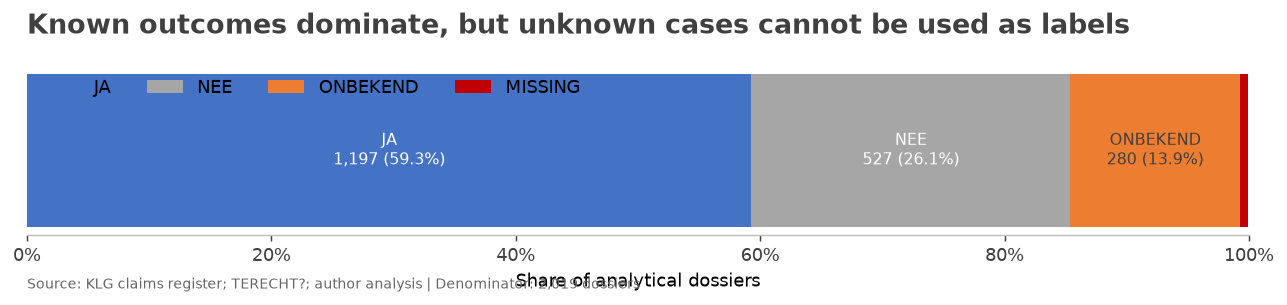

Among known JA/NEE outcomes: JA=1,197 (69.4%); NEE=527 (30.6%).


In [4]:
outcome = analysis["TERECHT?"].fillna("MISSING").value_counts()
outcome_share = outcome / outcome.sum() * 100
fig, ax = plt.subplots(figsize=(10, 2.7))
left=0
order=[x for x in ["JA","NEE","ONBEKEND","MISSING","NA"] if x in outcome.index]
colours={"JA":BLUE,"NEE":MID_GREY,"ONBEKEND":ORANGE,"MISSING":RED,"NA":RED}
for value in order:
    width=outcome_share[value]
    ax.barh(["All analytical dossiers"], [width], left=left, color=colours.get(value,MID_GREY), height=.45, label=value)
    if width >= 4: ax.text(left+width/2,0,f"{value}\n{outcome[value]:,} ({width:.1f}%)",ha="center",va="center",fontsize=9,color="white" if value in ["JA","NEE"] else DARK_GREY)
    left += width
ax.set_xlim(0,100); ax.xaxis.set_major_formatter(PercentFormatter()); ax.set_xlabel("Share of analytical dossiers")
ax.set_title("Known outcomes dominate, but unknown cases cannot be used as labels",loc="left",fontweight="bold",color=DARK_GREY,pad=18)
ax.text(0,-.32,"Source: KLG claims register; TERECHT?; author analysis | Denominator: 2,019 dossiers",transform=ax.transAxes,fontsize=8,color="#666666")
ax.spines["left"].set_visible(False); ax.spines["bottom"].set_color("#BFBFBF"); ax.set_yticks([]); ax.legend(ncol=len(order),loc="upper left",bbox_to_anchor=(0,1.02),frameon=False)
plt.tight_layout(); plt.show()

print(f"Among known JA/NEE outcomes: JA={known['TERECHT?'].eq('JA').sum():,} ({known['TERECHT?'].eq('JA').mean():.1%}); NEE={known['TERECHT?'].eq('NEE').sum():,} ({known['TERECHT?'].eq('NEE').mean():.1%}).")

## 4 | Incident profile and Pareto concentration

### What this chart answers
Are recorded claims driven by a few major incident labels, or spread evenly across many causes?

### How to read the chart
The bars show the number of cases for the 20 most frequent labels as entered in Excel. The orange line shows their cumulative share. The chart uses the raw labels deliberately: it shows why a controlled business dictionary is needed before modelling.

### Business meaning
If a small number of incident families explain most cases, prevention work can focus on them first. However, spelling variants such as `VERWISSELING`, `VERWISSESLING` and `VERWISSLING` must be mapped consistently. Keep the original label for auditability and create a new `incident_group` field for analysis.

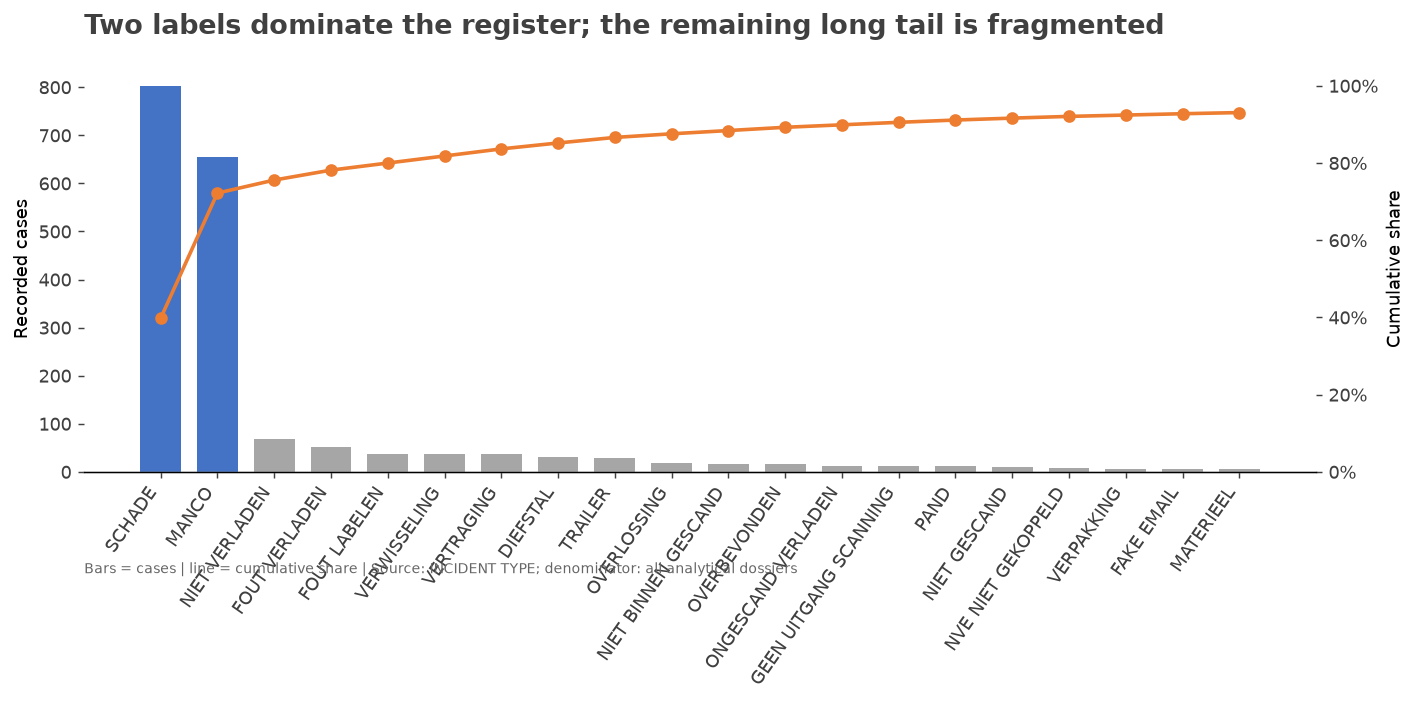

,incident,cases,share_%,cum_%
0,SCHADE,803,39.8,39.8
1,MANCO,655,32.4,72.2
2,NIET VERLADEN,68,3.4,75.6
3,FOUT VERLADEN,52,2.6,78.2
4,FOUT LABELEN,37,1.8,80.0
5,VERWISSELING,37,1.8,81.8
6,VERTRAGING,37,1.8,83.7
7,DIEFSTAL,31,1.5,85.2
8,TRAILER,29,1.4,86.6
9,OVERLOSSING,19,0.9,87.6


SCHADE + MANCO: 1,458 cases (72.2%).


In [5]:
incident = analysis["INCIDENT TYPE"].fillna("MISSING").value_counts()
pareto = incident.reset_index(); pareto.columns=["incident","cases"]
pareto["share_%"] = pareto["cases"] / pareto["cases"].sum() * 100
pareto["cum_%"] = pareto["share_%"].cumsum()

fig, ax1 = plt.subplots(figsize=(11,5.5))
show=pareto.head(20)
ax1.bar(range(len(show)), show["cases"], color=[BLUE if x in ["SCHADE","MANCO"] else MID_GREY for x in show["incident"]], width=.72)
ax1.set_xticks(range(len(show))); ax1.set_xticklabels(show["incident"],rotation=55,ha="right"); ax1.set_ylabel("Recorded cases")
ax1.set_title("Two labels dominate the register; the remaining long tail is fragmented",loc="left",fontweight="bold",color=DARK_GREY,pad=18)
ax2=ax1.twinx(); ax2.plot(range(len(show)),show["cum_%"],color=ORANGE,marker="o",linewidth=2); ax2.set_ylim(0,105); ax2.yaxis.set_major_formatter(PercentFormatter()); ax2.set_ylabel("Cumulative share")
ax1.text(0,-.25,"Bars = cases | line = cumulative share | Source: INCIDENT TYPE; denominator: all analytical dossiers",transform=ax1.transAxes,fontsize=8,color="#666666")
ax1.spines["bottom"].set_color("#BFBFBF"); ax2.spines["top"].set_visible(False); plt.tight_layout(); plt.show()

display(pareto.head(15))
print(f"SCHADE + MANCO: {incident.reindex(['SCHADE','MANCO']).fillna(0).sum():,} cases ({incident.reindex(['SCHADE','MANCO']).fillna(0).sum()/len(analysis):.1%}).")

## 5 | Parties: volume, concentration and the missing denominator

### What this chart answers
How concentrated are the recorded cases across carriers, principals, customers, senders and receivers?

### How to read the charts
The first chart shows the share of all recorded dossiers covered by the ten most frequent codes in each field. The second chart ranks the largest carrier codes by recorded case volume. Codes are categories, not measurements: carrier code 20 is not twice carrier code 10.

### Business meaning
High volume does not mean high risk. A carrier may have many cases because it handles many shipments. KLG must provide total shipments by carrier, customer and route before calculating a true claim rate. Rare codes should be pooled or regularised in a model.

,unique_codes,top_code,top_cases,top_10_share_%
field,,,,
Vervoerder getal,259,1,188,44.6
Opdraggever getal,465,3,149,28.7
Klantcode getal,379,3,143,26.9
afzender getal,851,4,141,22.9
ontvanger getal,1331,46,52,8.9


/var/folders/pt/qmvtwr7n04gfnygng_ks6vgm0000gn/T/ipykernel_8426/2603511730.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=1.5); plt.show()


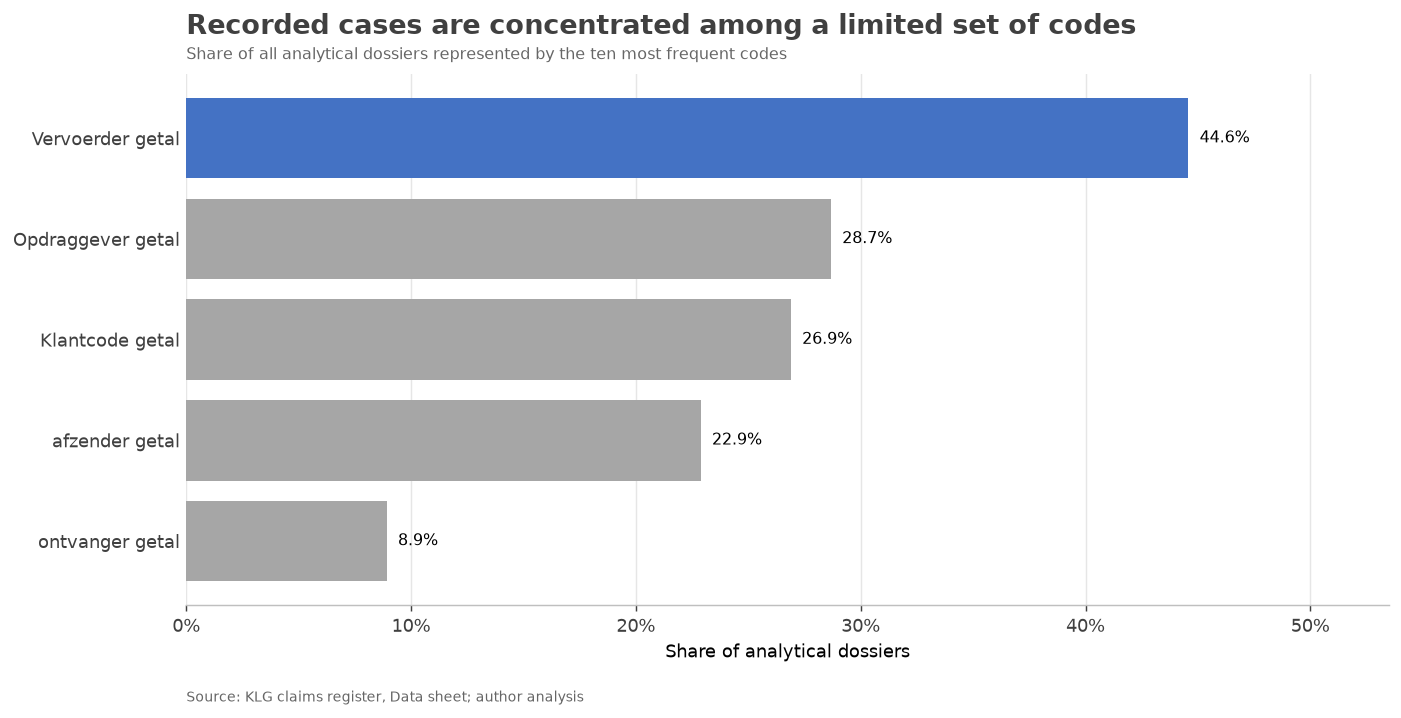

/var/folders/pt/qmvtwr7n04gfnygng_ks6vgm0000gn/T/ipykernel_8426/2603511730.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=1.5); plt.show()


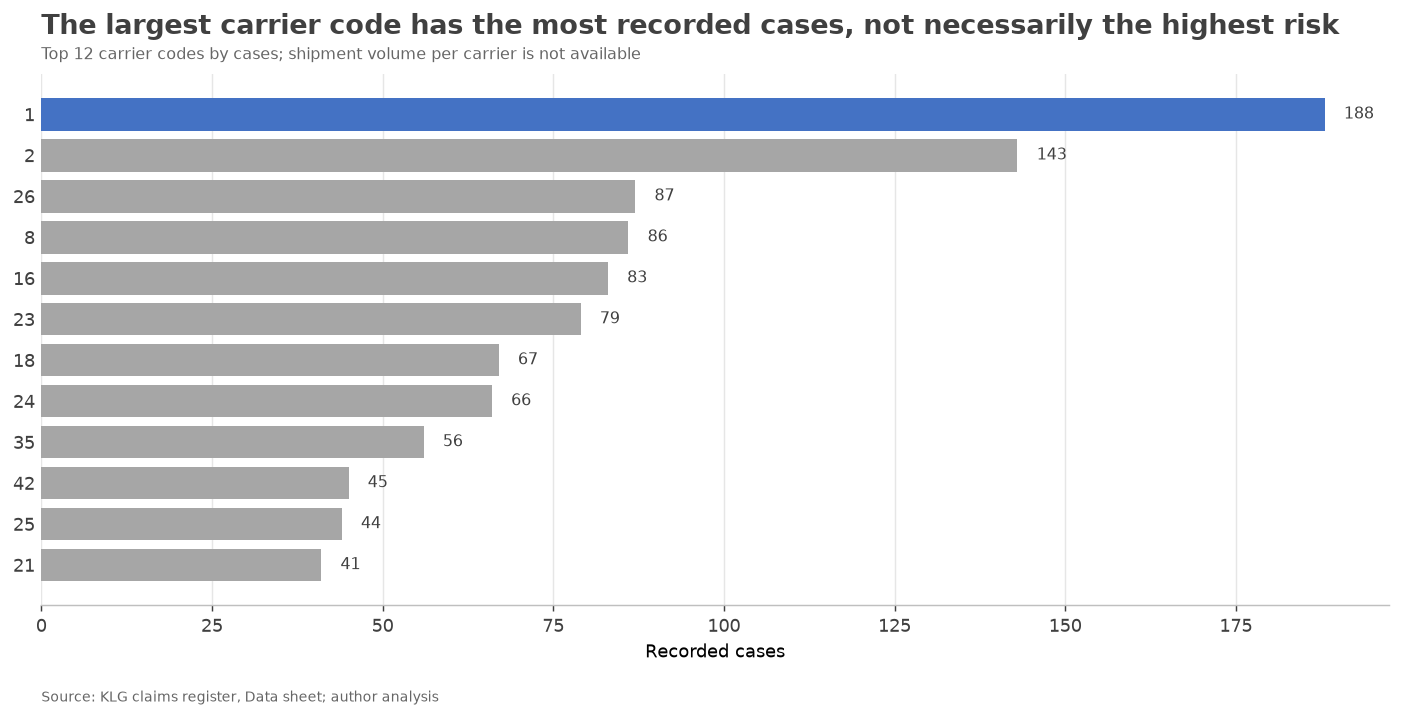

In [6]:
party_cols=["Vervoerder getal","Opdraggever getal","Klantcode getal","afzender getal","ontvanger getal"]
party_rows=[]
for c in party_cols:
    vc=analysis[c].value_counts(dropna=True)
    party_rows.append({"field":c,"unique_codes":vc.size,"top_code":vc.index[0],"top_cases":vc.iloc[0],"top_10_share_%":vc.head(10).sum()/len(analysis)*100})
party_summary=pd.DataFrame(party_rows).set_index("field")
display(party_summary.round(1))

fig,ax=chart_frame("Recorded cases are concentrated among a limited set of codes", "Share of all analytical dossiers represented by the ten most frequent codes")
ps=party_summary["top_10_share_%"].sort_values()
ax.barh(ps.index,ps.values,color=MID_GREY); ax.barh(["Vervoerder getal"],[ps["Vervoerder getal"]],color=BLUE)
for y,v in enumerate(ps): ax.text(v+.5,y,f"{v:.1f}%",va="center",fontsize=9)
ax.set_xlabel("Share of analytical dossiers"); ax.xaxis.set_major_formatter(PercentFormatter()); ax.set_xlim(0,max(ps)*1.2); finish(ax)

carrier=analysis["Vervoerder getal"].value_counts().head(12).sort_values()
fig,ax=chart_frame("The largest carrier code has the most recorded cases, not necessarily the highest risk", "Top 12 carrier codes by cases; shipment volume per carrier is not available")
ax.barh(carrier.index.astype(str),carrier.values,color=[BLUE if str(x)==str(carrier.index[-1]) else MID_GREY for x in carrier.index]); label_bars(ax); ax.set_xlabel("Recorded cases"); finish(ax)

## 6 | Time profile: workload volume versus risk rate

### What this chart answers
When do recorded cases appear in the register, and when is the claims team likely to have more workload?

### How to read the charts
The left chart follows calendar order by transport month. The right chart follows the week from Monday to Sunday. Labels show case counts, not percentages.

### Important limitation
These are workload charts, not risk charts. A month with more recorded cases may simply have more shipments. To calculate a monthly or weekday claim rate, we need the total number of shipments for the same period and segment.

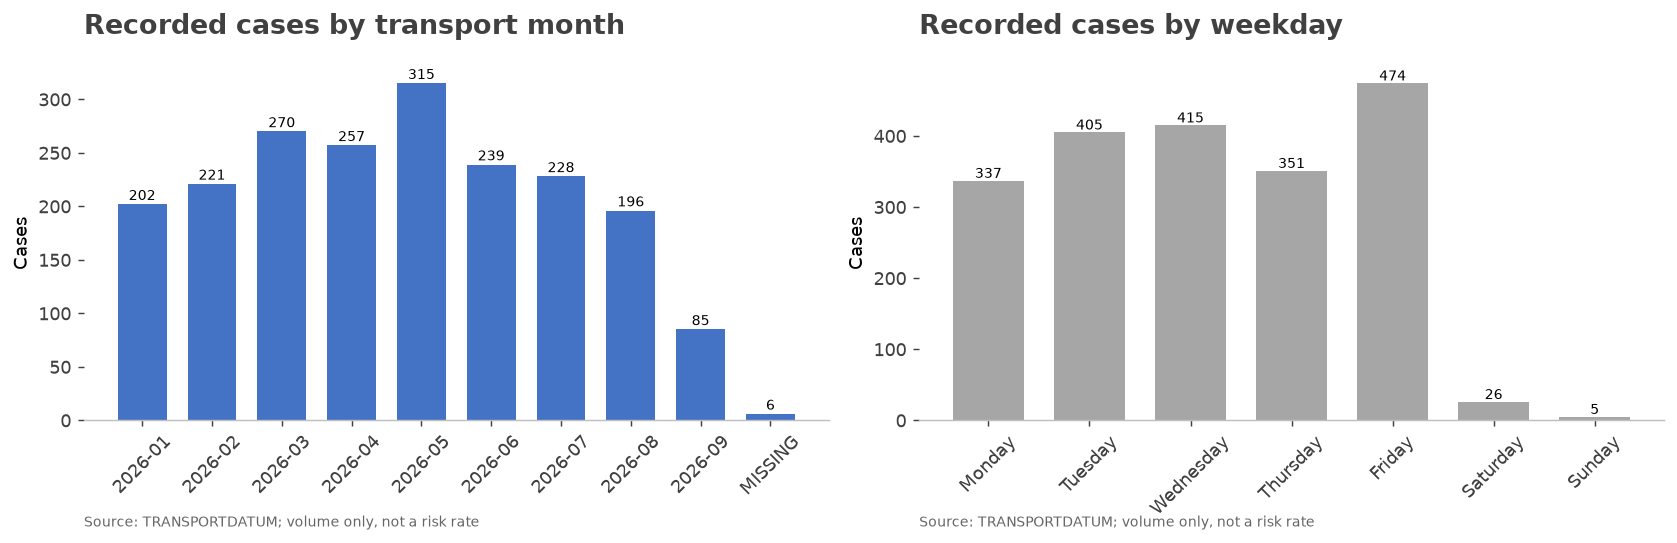

,month_cases
transport_month,
2026-01,202
2026-02,221
2026-03,270
2026-04,257
2026-05,315
2026-06,239
2026-07,228
2026-08,196
2026-09,85


In [7]:
month = analysis.assign(transport_month=analysis["transport_month"].fillna("MISSING")).groupby("transport_month").size().sort_index()
weekday_order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday=analysis["transport_weekday"].fillna("MISSING").value_counts().reindex(weekday_order).fillna(0)

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].bar(month.index.astype(str),month.values,color=BLUE,width=.7); axes[0].set_title("Recorded cases by transport month",loc="left",fontweight="bold",color=DARK_GREY); axes[0].set_ylabel("Cases"); axes[0].tick_params(axis="x",rotation=45)
for i,v in enumerate(month.values): axes[0].text(i,v+4,f"{v:,}",ha="center",fontsize=8)
axes[1].bar(weekday.index,weekday.values,color=MID_GREY,width=.7); axes[1].set_title("Recorded cases by weekday",loc="left",fontweight="bold",color=DARK_GREY); axes[1].set_ylabel("Cases"); axes[1].tick_params(axis="x",rotation=45)
for i,v in enumerate(weekday.values): axes[1].text(i,v+4,f"{v:,.0f}",ha="center",fontsize=8)
for ax in axes: ax.spines["bottom"].set_color("#BFBFBF"); ax.text(0,-.3,"Source: TRANSPORTDATUM; volume only, not a risk rate",transform=ax.transAxes,fontsize=8,color="#666666")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"month_cases":month}))

## 7 | Outcome rate by incident group

### What this chart answers
Among cases with a known `JA` or `NEE` outcome, which incident labels have the highest share of justified claims?

### How to read the charts
Only groups with at least 10 known cases are shown. The bar length is the `JA` share among known outcomes, not the share of all dossiers. The `n=` label gives the group size, so a 90% rate with `n=10` is visibly different from 90% with `n=300`. The 100% stacked chart shows the corresponding `JA` and `NEE` mix.

### Business meaning
This can help prioritise investigation types, but it is descriptive rather than causal. Rare categories remain unstable, and the result should be validated on a future time period before changing process rules.

,cases,ja,nee,ja_rate_%
INCIDENT TYPE,,,,
ONGESCAND VERLADEN,12,12,0,100.0
PAND,12,12,0,100.0
NIET GESCAND,10,10,0,100.0
DIEFSTAL,31,30,1,96.8
NIET VERLADEN,67,64,3,95.5
FOUT LABELEN,34,32,2,94.1
FOUT VERLADEN,50,47,3,94.0
NIET BINNEN GESCAND,16,15,1,93.8
GEEN UITGANG SCANNING,12,11,1,91.7


/var/folders/pt/qmvtwr7n04gfnygng_ks6vgm0000gn/T/ipykernel_8426/2603511730.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=1.5); plt.show()


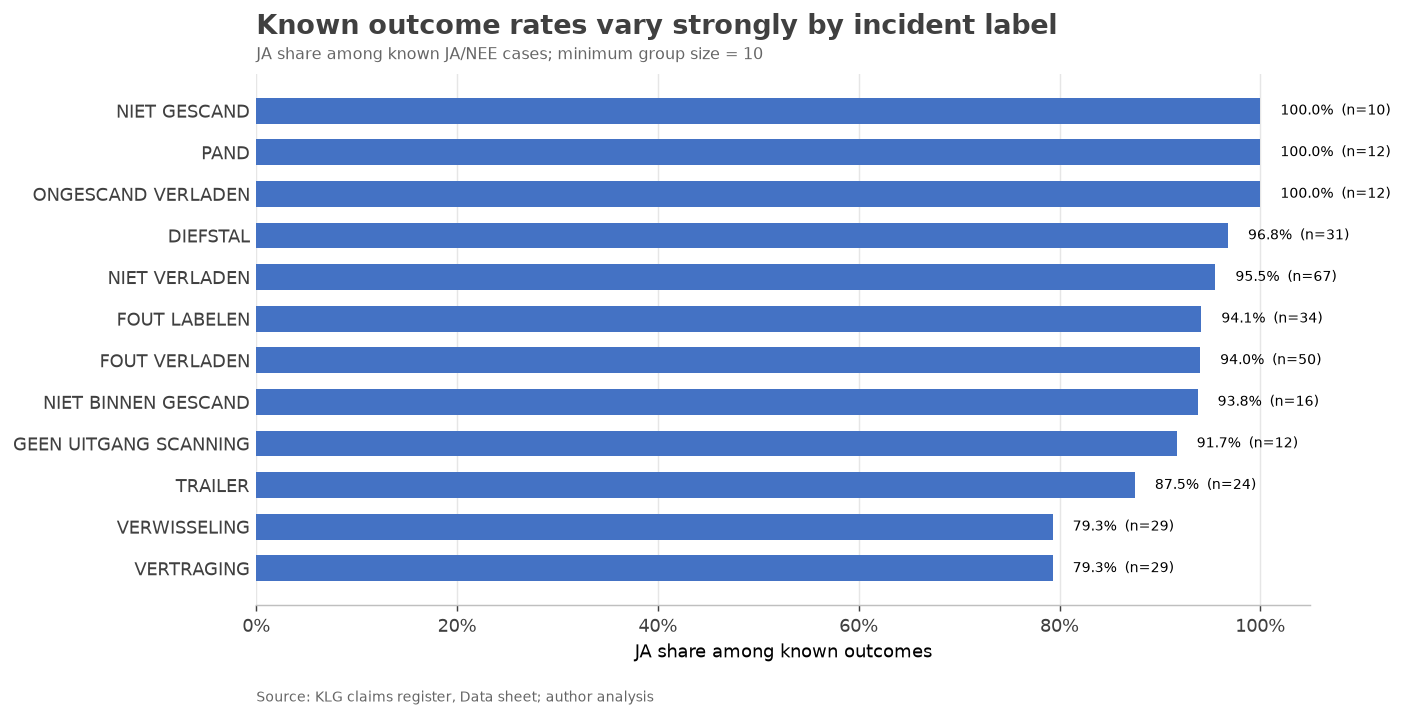

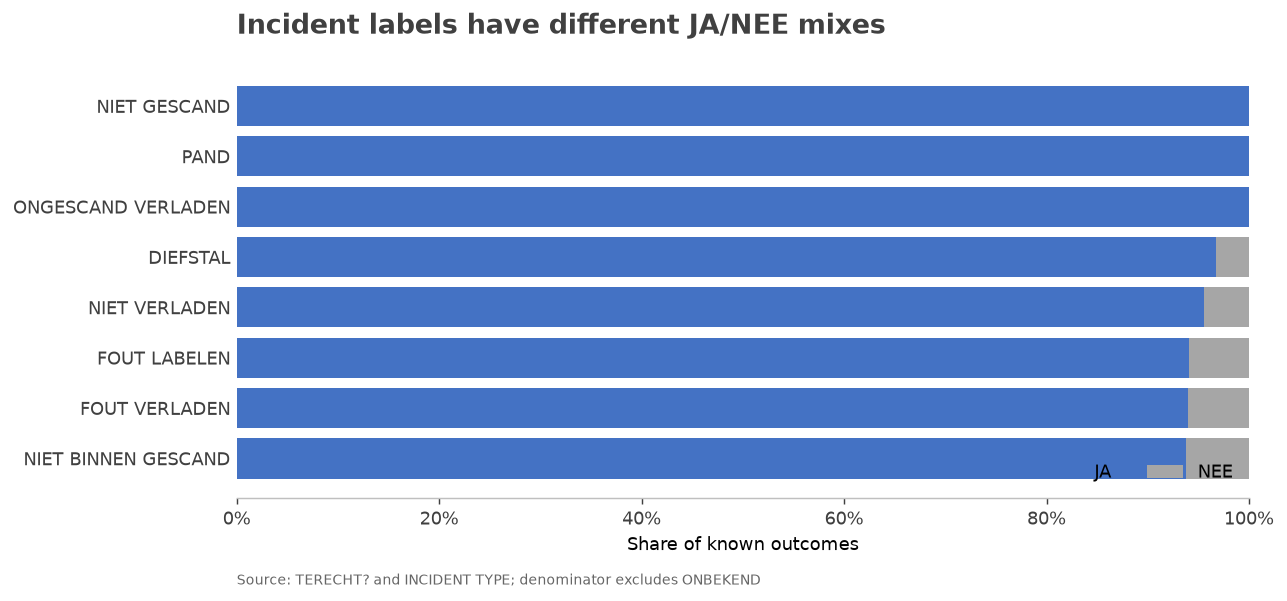

In [8]:
def outcome_rate(data, group_col, min_cases=10):
    x=data[data["TERECHT?"].isin(["JA","NEE"])].copy()
    g=x.groupby(group_col)["TERECHT?"].agg(cases="size",ja=lambda s:(s=="JA").sum())
    g["nee"]=g["cases"]-g["ja"]; g["ja_rate_%"]=g["ja"]/g["cases"]*100
    return g[g["cases"]>=min_cases].sort_values(["ja_rate_%","cases"],ascending=[False,False])

incident_rate=outcome_rate(analysis,"INCIDENT TYPE")
display(incident_rate.head(15).round(1))
plot=incident_rate.head(12).sort_values("ja_rate_%")
fig,ax=chart_frame("Known outcome rates vary strongly by incident label", "JA share among known JA/NEE cases; minimum group size = 10")
ax.barh(plot.index,plot["ja_rate_%"],color=BLUE,height=.62); ax.set_xlim(0,105); ax.xaxis.set_major_formatter(PercentFormatter()); ax.set_xlabel("JA share among known outcomes")
for y,v,n in zip(range(len(plot)),plot["ja_rate_%"],plot["cases"]): ax.text(v+2,y,f"{v:.1f}%  (n={n})",va="center",fontsize=8)
finish(ax)

# 100% stacked outcome view for the largest incident labels
stack=incident_rate.head(8).sort_values("ja_rate_%")
fig,ax=plt.subplots(figsize=(10,4.8)); ax.barh(stack.index,stack["ja"]/stack["cases"]*100,color=BLUE,label="JA"); ax.barh(stack.index,stack["nee"]/stack["cases"]*100,left=stack["ja"]/stack["cases"]*100,color=MID_GREY,label="NEE")
ax.set_xlim(0,100); ax.xaxis.set_major_formatter(PercentFormatter()); ax.set_xlabel("Share of known outcomes"); ax.set_title("Incident labels have different JA/NEE mixes",loc="left",fontweight="bold",color=DARK_GREY,pad=18); ax.legend(frameon=False,ncol=2,loc="lower right")
ax.text(0,-.2,"Source: TERECHT? and INCIDENT TYPE; denominator excludes ONBEKEND",transform=ax.transAxes,fontsize=8,color="#666666"); ax.spines["bottom"].set_color("#BFBFBF"); ax.tick_params(axis="y",length=0); plt.tight_layout(); plt.show()

## 8 | Responsibility fields: useful for diagnosis, unsafe for first-arrival prediction

### What this chart answers
How strongly do responsibility fields separate known outcomes?

### Why this is not a model recommendation
`Veroorzaker getal`, `Vervoerder veroorzaker` and `Afzender veroorzaker` are normally filled after investigation. Their strong separation is expected because they contain information close to the final decision.

### Business meaning
Use these fields for root-cause analysis and supplier/process review after a case is investigated. Exclude them from a model intended to score a claim at arrival; otherwise the model will learn from information that is not available at decision time.

,field,value,cases,known_cases,JA_rate_%
0,Vervoerder veroorzaker,NEE,1300,1101,59.0
1,Vervoerder veroorzaker,JA,715,619,87.7
2,Vervoerder veroorzaker,MISSING,4,4,100.0
3,Afzender veroorzaker,NEE,1655,1395,85.6
4,Afzender veroorzaker,JA,364,329,0.9
5,Veroorzaker getal,2,608,530,96.6
6,Veroorzaker getal,1,364,329,0.9
7,Veroorzaker getal,22,76,67,1.5
8,Veroorzaker getal,8,75,67,82.1
9,Veroorzaker getal,25,66,17,58.8


/var/folders/pt/qmvtwr7n04gfnygng_ks6vgm0000gn/T/ipykernel_8426/2603511730.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=1.5); plt.show()


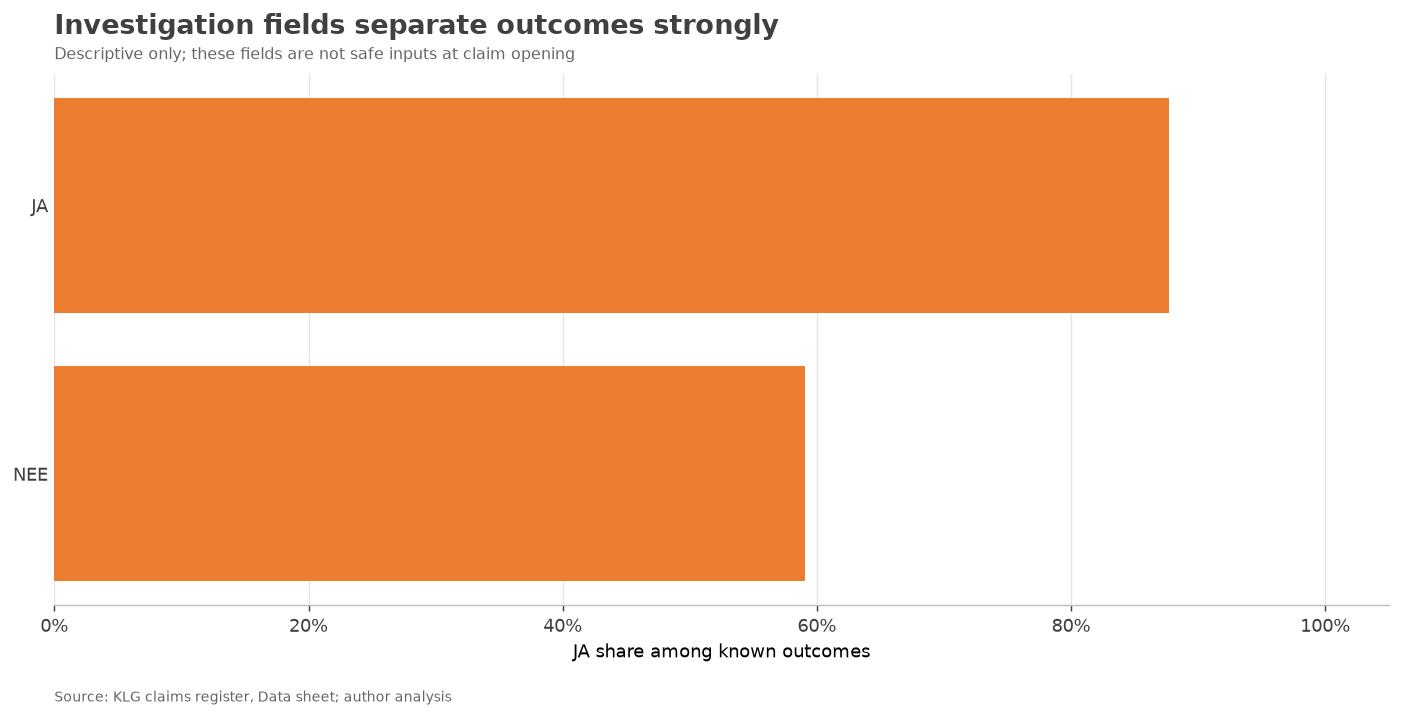

In [9]:
responsibility_cols=["Vervoerder veroorzaker","Afzender veroorzaker","Veroorzaker getal"]
rows=[]
for c in responsibility_cols:
    for value,n in analysis[c].fillna("MISSING").value_counts().head(8).items():
        subset=known[known[c].fillna("MISSING")==value]
        rows.append({"field":c,"value":value,"cases":n,"known_cases":len(subset),"JA_rate_%":(subset["TERECHT?"].eq("JA").mean()*100 if len(subset) else np.nan)})
responsibility=pd.DataFrame(rows)
display(responsibility.head(20).round(1))
fig,ax=chart_frame("Investigation fields separate outcomes strongly", "Descriptive only; these fields are not safe inputs at claim opening")
carrier_resp=outcome_rate(analysis,"Vervoerder veroorzaker",min_cases=10).sort_values("ja_rate_%")
ax.barh(carrier_resp.index.astype(str),carrier_resp["ja_rate_%"],color=ORANGE); ax.set_xlim(0,105); ax.xaxis.set_major_formatter(PercentFormatter()); ax.set_xlabel("JA share among known outcomes"); finish(ax)

## 9 | Route and geography views

### What this chart answers
Which sender-to-receiver country pairs and receiver-country codes account for the largest number of recorded cases?

### How to read the charts
The route chart combines the stored sender-country and receiver-country codes into a readable pair. The country chart ranks receiver-country codes by recorded case volume.

### Business meaning
Geography can help create a stable route feature, but it is not evidence that a route is unsafe. A proper route comparison needs the total shipments on each route and a consistent country-code dictionary.

,afzender getal land,ontvanger getal land,cases,route
12,2,6,267,2 → 6
7,2,1,151,2 → 1
8,2,2,141,2 → 2
18,2,12,104,2 → 12
11,2,5,99,2 → 5
16,2,10,99,2 → 10
15,2,9,74,2 → 9
0,1,1,69,1 → 1
24,2,18,64,2 → 18
99,7,1,46,7 → 1


/var/folders/pt/qmvtwr7n04gfnygng_ks6vgm0000gn/T/ipykernel_8426/2603511730.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=1.5); plt.show()


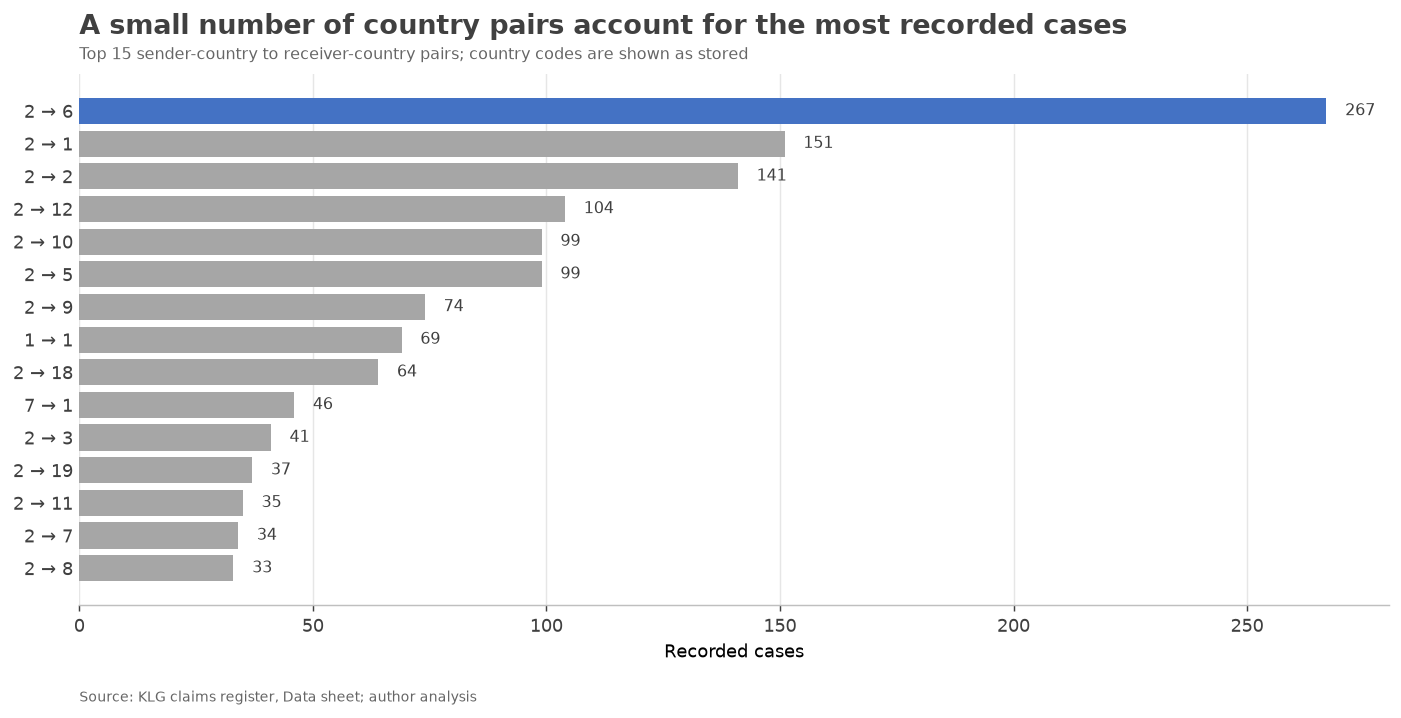

/var/folders/pt/qmvtwr7n04gfnygng_ks6vgm0000gn/T/ipykernel_8426/2603511730.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=1.5); plt.show()


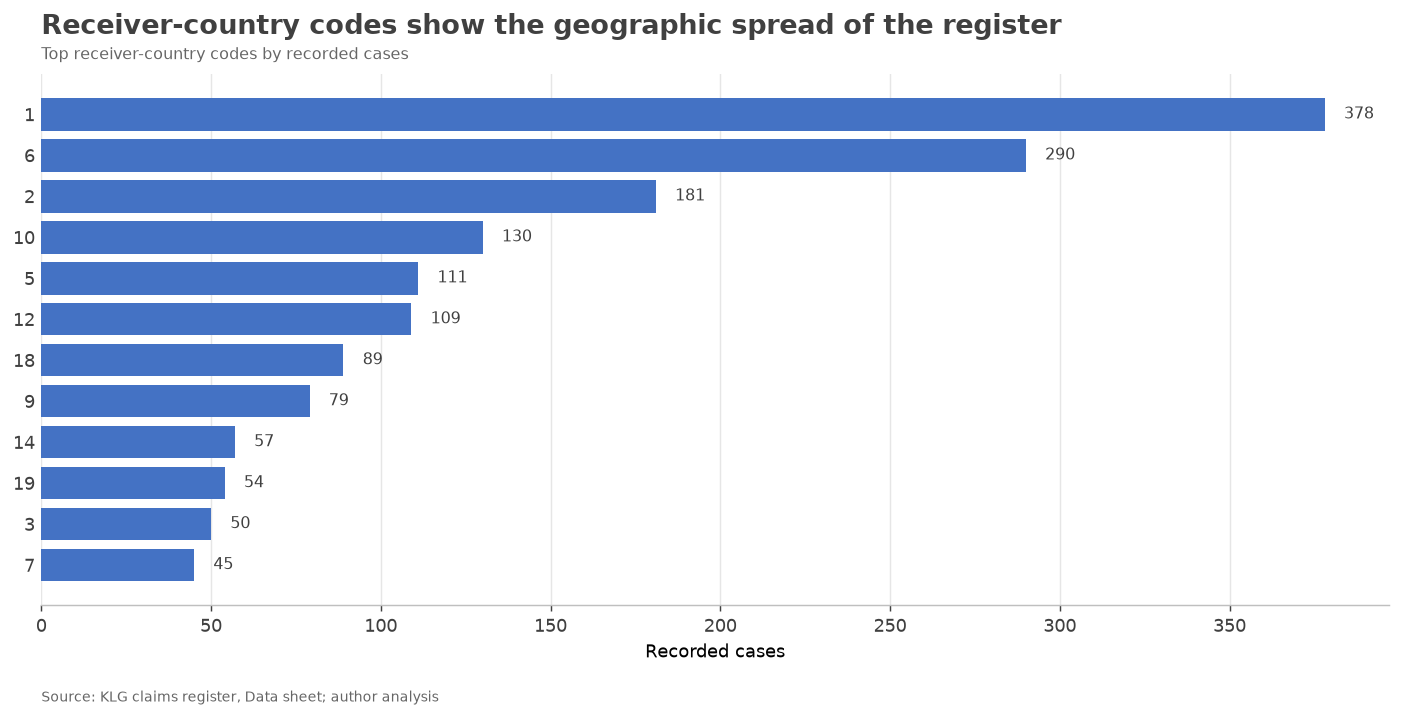

In [10]:
route_cols=["afzender getal land","ontvanger getal land"]
route=analysis.groupby(route_cols,dropna=False).size().reset_index(name="cases").sort_values("cases",ascending=False)
route["route"]=route[route_cols[0]].astype("string")+" → "+route[route_cols[1]].astype("string")
display(route.head(15))
fig,ax=chart_frame("A small number of country pairs account for the most recorded cases", "Top 15 sender-country to receiver-country pairs; country codes are shown as stored")
show=route.head(15).sort_values("cases"); ax.barh(show["route"],show["cases"],color=MID_GREY); ax.barh([show.iloc[-1]["route"]],[show.iloc[-1]["cases"]],color=BLUE); label_bars(ax); ax.set_xlabel("Recorded cases"); finish(ax)

country=analysis["ontvanger getal land"].value_counts().head(12).sort_values()
fig,ax=chart_frame("Receiver-country codes show the geographic spread of the register", "Top receiver-country codes by recorded cases")
ax.barh(country.index.astype(str),country.values,color=BLUE); label_bars(ax); ax.set_xlabel("Recorded cases"); finish(ax)

## 10 | Operational status and closure fields

### What this chart answers
How are cases distributed across process-status fields such as open status, customer action and external reporting?

### How to read the small multiples
Each panel is one field. The bars show counts in the same analytical base. Red highlights missing or invalid values; grey provides the normal context. Comparing panels is not a comparison of risk because the fields measure different processes.

### Business meaning
These fields are useful for backlog, workflow and data-quality monitoring. They should not be used as predictors of whether a new claim is justified if they are updated after claim opening.

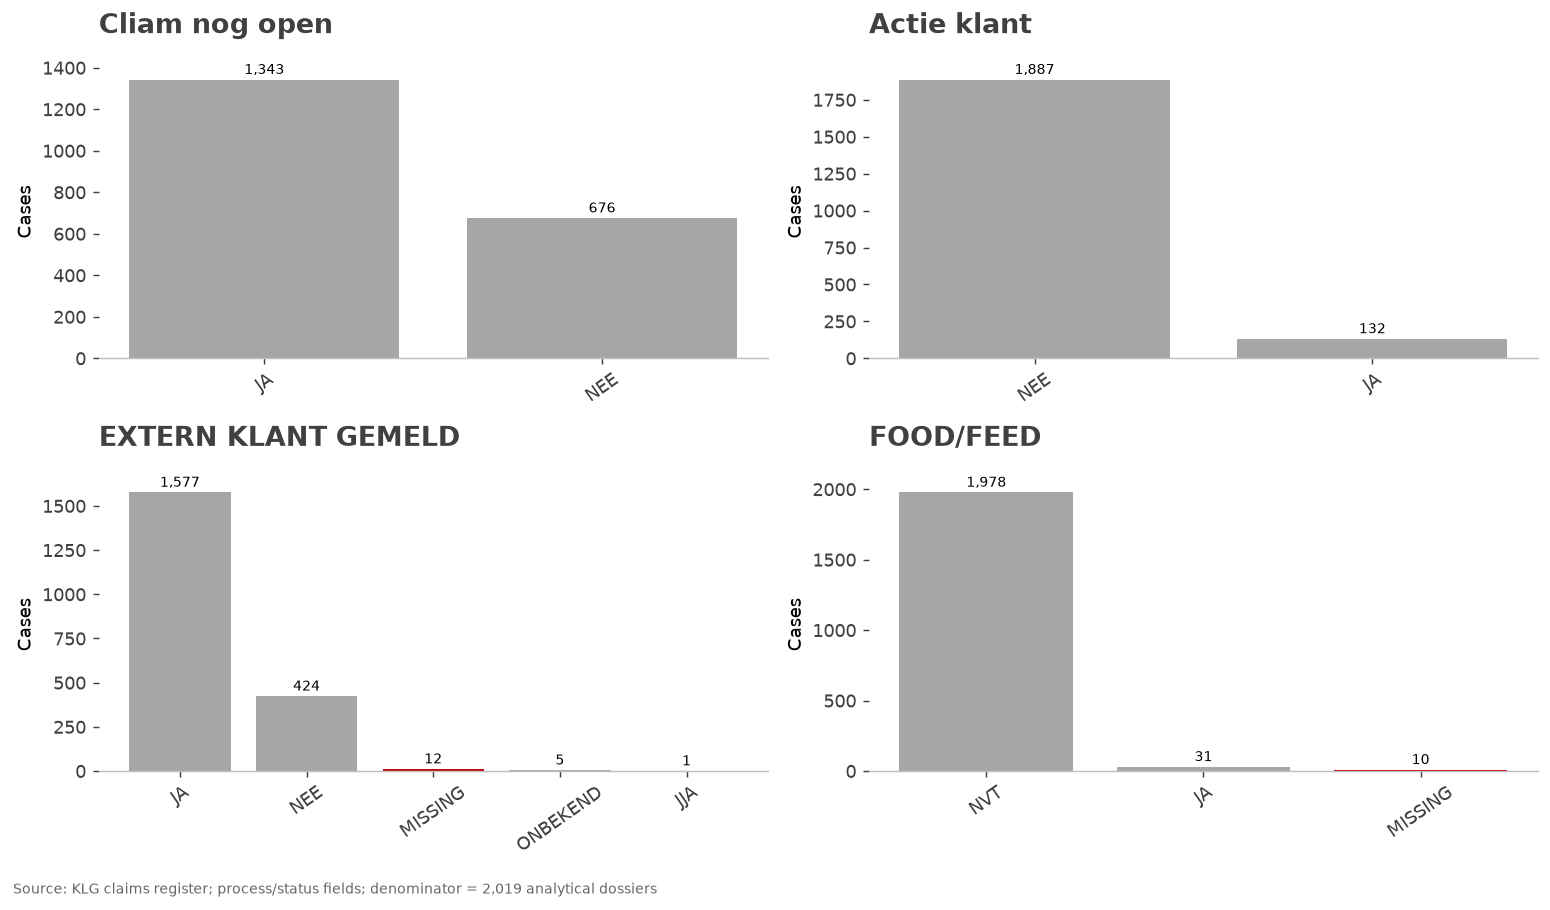

,Cliam nog open,Actie klant,EXTERN KLANT GEMELD,FOOD/FEED
JA,1343,132,1577,31
JJA,0,0,1,0
MISSING,0,0,12,10
NEE,676,1887,424,0
NVT,0,0,0,1978
ONBEKEND,0,0,5,0


In [11]:
status_cols=["Cliam nog open","Actie klant","EXTERN KLANT GEMELD","FOOD/FEED"]
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,col in zip(axes.flat,status_cols):
    vc=analysis[col].fillna("MISSING").value_counts()
    ax.bar(vc.index.astype(str),vc.values,color=[RED if str(x) in ["MISSING","#REF!"] else MID_GREY for x in vc.index])
    ax.set_title(col,loc="left",fontweight="bold",color=DARK_GREY); ax.set_ylabel("Cases"); ax.tick_params(axis="x",rotation=35)
    for i,v in enumerate(vc.values): ax.text(i,v+max(vc.values)*.02,f"{v:,}",ha="center",fontsize=8)
    ax.spines["bottom"].set_color("#BFBFBF")
fig.text(.01,.01,"Source: KLG claims register; process/status fields; denominator = 2,019 analytical dossiers",fontsize=8,color="#666666"); plt.tight_layout(rect=[0, .03, 1, 1]); plt.show()

status_summary=pd.DataFrame({c:analysis[c].fillna("MISSING").value_counts() for c in status_cols}).fillna(0).astype(int)
display(status_summary)

## 11 | Model-ready feature boundary

### Why this table is included
EDA is only useful when it leads to a safe next step. This table translates the findings into a modelling boundary based on one question: **was this value available when the claim arrived?**

### How to use it
Keep raw fields in the audit copy, create cleaned replacements where needed, and exclude post-investigation fields from the first-arrival model. This prevents target leakage and makes the model usable in the real workflow.

In [12]:
model_boundary=pd.DataFrame([
    ("INCIDENT TYPE / incident_group","Keep transformed","Known at opening; group spelling variants."),
    ("Vervoerder getal","Keep categorical","Use pooling/regularisation for rare codes."),
    ("Opdraggever / Klantcode","Keep after definition","Confirm business meaning first."),
    ("Country route","Keep categorical","Create sender_country → receiver_country."),
    ("TRANSPORTDATUM features","Keep","Month/weekday are context only."),
    ("EXTERN KLANT GEMELD","Conditional","Keep only if timestamp confirms it is known at opening."),
    ("Veroorzaker getal","Exclude","Post-investigation target leakage."),
    ("Vervoerder/Afzender veroorzaker","Exclude","Post-investigation responsibility fields."),
    ("DATUM AF / Cliam nog open / Actie klant","Exclude","Outcome/process fields after opening."),
    ("KOSTEN INTERN","Exclude initially","31 numeric values; too sparse for first model.")
],columns=["Field","Decision","Reason"])
display(model_boundary)

,Field,Decision,Reason
0,INCIDENT TYPE / incident_group,Keep transformed,Known at opening; group spelling varia...
1,Vervoerder getal,Keep categorical,Use pooling/regularisation for rare co...
2,Opdraggever / Klantcode,Keep after definition,Confirm business meaning first.
3,Country route,Keep categorical,Create sender_country → receiver_country.
4,TRANSPORTDATUM features,Keep,Month/weekday are context only.
5,EXTERN KLANT GEMELD,Conditional,Keep only if timestamp confirms it is ...
6,Veroorzaker getal,Exclude,Post-investigation target leakage.
7,Vervoerder/Afzender veroorzaker,Exclude,Post-investigation responsibility fields.
8,DATUM AF / Cliam nog open / Actie klant,Exclude,Outcome/process fields after opening.
9,KOSTEN INTERN,Exclude initially,31 numeric values; too sparse for firs...


## 12 | Decision-ready conclusions

### What the EDA supports now
The current file can support a transparent prioritisation model for claims that have already arrived. It can describe incident concentration, workload volume, data quality and known-outcome patterns.

### What the EDA does not support yet
It cannot prove that one carrier, customer or route has a higher shipment risk, because normal shipments and exposure denominators are missing. It also cannot justify automatic approval or rejection of claims.

### Recommended next action
Clean and document the current register, validate the incident dictionary with KLG, build a leakage-safe baseline model, and request all-shipment data before moving to true shipment-risk prediction.